In [2]:
# Load the saved protocol and ArcFace embeddings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/results"
)

data_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/data"
)

gallery_probe_split = pd.read_csv(
    data_directory / "lfw_gallery_probe_split.csv"
)

gallery_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "gallery"
].copy()

probe_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "probe"
].copy()

gallery_identity_ids = (
    gallery_metadata["identity_id"].to_numpy()
)

probe_identity_ids = (
    probe_metadata["identity_id"].to_numpy()
)

gallery_embeddings = np.load(
    results_directory / "gallery_arcface_embeddings.npy"
)

clean_probe_embeddings = np.load(
    results_directory / "probe_arcface_embeddings.npy"
)

print(f"Gallery embeddings: {gallery_embeddings.shape}")
print(f"Clean probe embeddings: {clean_probe_embeddings.shape}")
print(f"Probe identities: {len(np.unique(probe_identity_ids))}")

Gallery embeddings: (1269, 512)
Clean probe embeddings: (846, 512)
Probe identities: 423


In [3]:
# Reconstruct normalized gallery templates

def normalize_vectors(vectors):
    norms = np.linalg.norm(
        vectors,
        axis=1,
        keepdims=True
    )

    return vectors / np.maximum(
        norms,
        1e-12
    )


template_identity_ids = np.sort(
    gallery_metadata["identity_id"].unique()
)

gallery_templates = []

for identity_id in template_identity_ids:
    identity_embeddings = gallery_embeddings[
        gallery_identity_ids == identity_id
    ]

    identity_template = identity_embeddings.mean(
        axis=0,
        keepdims=True
    )

    gallery_templates.append(
        normalize_vectors(identity_template)[0]
    )

gallery_templates = np.vstack(
    gallery_templates
)

print(f"Gallery template matrix: {gallery_templates.shape}")

Gallery template matrix: (423, 512)


In [4]:
# Define per-probe identification failure analysis

def analyze_probe_embeddings(
    embeddings,
    condition,
    degradation,
    severity
):
    similarity_matrix = (
        embeddings @ gallery_templates.T
    )

    ranked_positions = np.argsort(
        similarity_matrix,
        axis=1
    )[:, ::-1]

    ranked_identity_ids = (
        template_identity_ids[ranked_positions]
    )

    true_ranks = []

    for row_index, true_identity_id in enumerate(
        probe_identity_ids
    ):
        rank = np.where(
            ranked_identity_ids[row_index]
            == true_identity_id
        )[0][0] + 1

        true_ranks.append(rank)

    true_ranks = np.array(true_ranks)

    true_template_positions = np.array([
        np.where(
            template_identity_ids == identity_id
        )[0][0]
        for identity_id in probe_identity_ids
    ])

    true_similarity = similarity_matrix[
        np.arange(len(probe_identity_ids)),
        true_template_positions
    ]

    strongest_impostor_similarity = []

    for row_index, true_position in enumerate(
        true_template_positions
    ):
        impostor_scores = np.delete(
            similarity_matrix[row_index],
            true_position
        )

        strongest_impostor_similarity.append(
            impostor_scores.max()
        )

    strongest_impostor_similarity = np.array(
        strongest_impostor_similarity
    )

    similarity_margin = (
        true_similarity
        - strongest_impostor_similarity
    )

    rank_1_correct = true_ranks == 1
    rank_5_correct = true_ranks <= 5

    failure_type = np.select(
        [
            rank_1_correct,
            rank_5_correct,
            similarity_margin < 0
        ],
        [
            "correct_rank_1",
            "correct_within_rank_5",
            "negative_similarity_margin"
        ],
        default="rank_5_failure"
    )

    return pd.DataFrame({
        "probe_index": probe_metadata["image_index"].to_numpy(),
        "true_identity_id": probe_identity_ids,
        "predicted_identity_id": (
            ranked_identity_ids[:, 0]
        ),
        "true_rank": true_ranks,
        "true_similarity": true_similarity,
        "strongest_impostor_similarity": (
            strongest_impostor_similarity
        ),
        "similarity_margin": similarity_margin,
        "rank_1_correct": rank_1_correct,
        "rank_5_correct": rank_5_correct,
        "failure_type": failure_type,
        "condition": condition,
        "degradation": degradation,
        "severity": severity
    })

In [5]:
# Analyze clean and degraded probe embeddings

condition_results = []

condition_results.append(
    analyze_probe_embeddings(
        clean_probe_embeddings,
        "clean_baseline",
        "clean_baseline",
        "none"
    )
)

embedding_files = sorted(
    results_directory.glob(
        "probe_embeddings_*.npy"
    )
)

for embedding_file in embedding_files:
    condition_name = (
        embedding_file.stem
        .replace("probe_embeddings_", "")
    )

    degradation, severity = condition_name.rsplit(
        "_",
        1
    )

    condition_embeddings = np.load(
        embedding_file
    )

    condition_results.append(
        analyze_probe_embeddings(
            condition_embeddings,
            condition_name,
            degradation,
            severity
        )
    )

failure_analysis = pd.concat(
    condition_results,
    ignore_index=True
)

print(
    f"Analyzed rows: {len(failure_analysis)}"
)

display(
    failure_analysis.head()
)

Analyzed rows: 10998


,probe_index,true_identity_id,predicted_identity_id,true_rank,true_similarity,strongest_impostor_similarity,similarity_margin,rank_1_correct,rank_5_correct,failure_type,condition,degradation,severity
0,2754,0,0,1,0.419534,0.319055,0.100479,True,True,correct_rank_1,clean_baseline,clean_baseline,none
1,4556,0,0,1,0.393839,0.292321,0.101518,True,True,correct_rank_1,clean_baseline,clean_baseline,none
2,2245,1,1,1,0.429566,0.225111,0.204455,True,True,correct_rank_1,clean_baseline,clean_baseline,none
3,1850,1,1,1,0.520932,0.230011,0.290921,True,True,correct_rank_1,clean_baseline,clean_baseline,none
4,5922,2,2,1,0.719464,0.224297,0.495167,True,True,correct_rank_1,clean_baseline,clean_baseline,none


In [6]:
# Compare failure rates across degradation conditions

failure_summary = (
    failure_analysis
    .groupby(
        [
            "condition",
            "degradation",
            "severity"
        ]
    )
    .agg(
        rank_1_accuracy=(
            "rank_1_correct",
            "mean"
        ),
        rank_5_accuracy=(
            "rank_5_correct",
            "mean"
        ),
        mean_true_rank=(
            "true_rank",
            "mean"
        ),
        mean_similarity_margin=(
            "similarity_margin",
            "mean"
        ),
        negative_margin_count=(
            "similarity_margin",
            lambda values: (values < 0).sum()
        ),
        rank_5_failure_count=(
            "true_rank",
            lambda values: (values > 5).sum()
        )
    )
    .reset_index()
)

display(failure_summary)

,condition,degradation,severity,rank_1_accuracy,rank_5_accuracy,mean_true_rank,mean_similarity_margin,negative_margin_count,rank_5_failure_count
0,blur_mild,blur,mild,0.958629,0.977541,2.011820,0.285450,35,19
1,blur_moderate,blur,moderate,0.947991,0.972813,2.416076,0.237960,44,23
2,blur_severe,blur,severe,0.882979,0.949173,4.062648,0.146183,99,43
3,clean_baseline,clean_baseline,none,0.958629,0.978723,2.003546,0.288064,35,18
4,illumination_mild,illumination,mild,0.958629,0.977541,2.057920,0.287635,35,19
5,illumination_moderate,illumination,moderate,0.953901,0.975177,2.117021,0.285236,39,21
6,illumination_severe,illumination,severe,0.949173,0.972813,2.270686,0.279651,43,23
7,jpeg_compression_mild,jpeg_compression,mild,0.953901,0.976359,2.000000,0.282579,39,20
8,jpeg_compression_moderate,jpeg_compression,moderate,0.952719,0.973995,2.198582,0.270869,40,22
9,jpeg_compression_severe,jpeg_compression,severe,0.919622,0.955083,3.433806,0.201009,68,38


In [7]:
# Identify new Rank-1 failures relative to the clean baseline

clean_status = (
    failure_analysis[
        failure_analysis["condition"]
        == "clean_baseline"
    ][
        [
            "probe_index",
            "rank_1_correct",
            "true_rank"
        ]
    ]
    .rename(columns={
        "rank_1_correct": "clean_rank_1_correct",
        "true_rank": "clean_true_rank"
    })
)

failure_analysis = failure_analysis.merge(
    clean_status,
    on="probe_index",
    how="left"
)

failure_analysis["new_rank_1_failure"] = (
    failure_analysis["clean_rank_1_correct"]
    & ~failure_analysis["rank_1_correct"]
)

new_failure_summary = (
    failure_analysis[
        failure_analysis["condition"]
        != "clean_baseline"
    ]
    .groupby(
        [
            "condition",
            "degradation",
            "severity"
        ]
    )
    .agg(
        new_rank_1_failures=(
            "new_rank_1_failure",
            "sum"
        ),
        new_rank_1_failure_rate=(
            "new_rank_1_failure",
            "mean"
        )
    )
    .reset_index()
)

display(new_failure_summary)

,condition,degradation,severity,new_rank_1_failures,new_rank_1_failure_rate
0,blur_mild,blur,mild,3,0.003546
1,blur_moderate,blur,moderate,16,0.018913
2,blur_severe,blur,severe,71,0.083924
3,illumination_mild,illumination,mild,0,0.000000
4,illumination_moderate,illumination,moderate,5,0.005910
5,illumination_severe,illumination,severe,10,0.011820
6,jpeg_compression_mild,jpeg_compression,mild,4,0.004728
7,jpeg_compression_moderate,jpeg_compression,moderate,8,0.009456
8,jpeg_compression_severe,jpeg_compression,severe,37,0.043735
9,resolution_reduction_mild,resolution_reduction,mild,0,0.000000


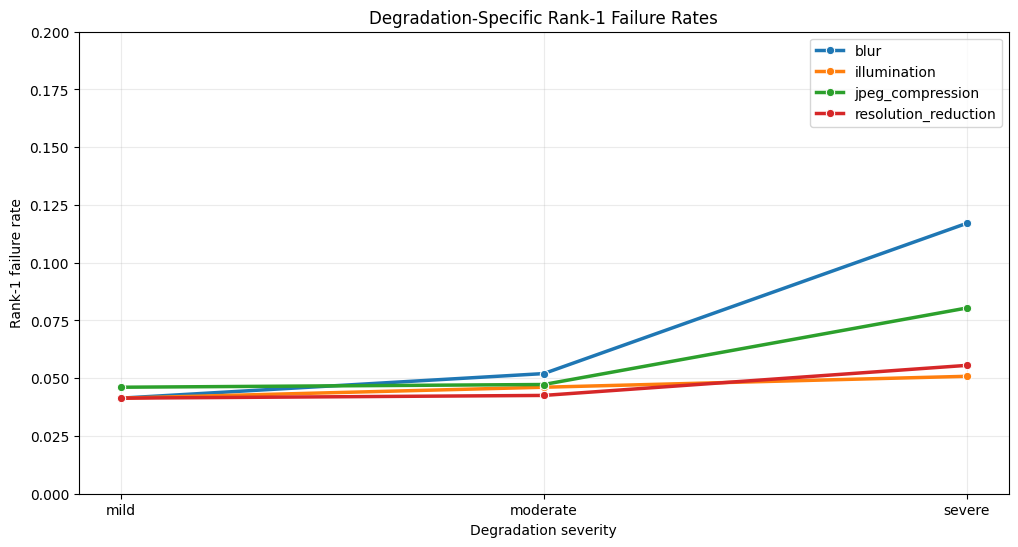

In [8]:
# Plot failure rates by degradation severity

plot_data = failure_summary[
    failure_summary["condition"]
    != "clean_baseline"
].copy()

plot_data["rank_1_failure_rate"] = (
    1 - plot_data["rank_1_accuracy"]
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=plot_data,
    x="severity",
    y="rank_1_failure_rate",
    hue="degradation",
    marker="o",
    linewidth=2.5
)

plt.xlabel("Degradation severity")
plt.ylabel("Rank-1 failure rate")
plt.title(
    "Degradation-Specific Rank-1 Failure Rates"
)
plt.ylim(0, 0.2)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

In [9]:
# Display the most difficult degraded probes

hardest_probes = (
    failure_analysis[
        failure_analysis["condition"]
        != "clean_baseline"
    ]
    .sort_values(
        [
            "similarity_margin",
            "true_rank"
        ]
    )
    [
        [
            "condition",
            "probe_index",
            "true_identity_id",
            "predicted_identity_id",
            "true_rank",
            "true_similarity",
            "strongest_impostor_similarity",
            "similarity_margin",
            "failure_type"
        ]
    ]
    .head(20)
)

display(hardest_probes)

,condition,probe_index,true_identity_id,predicted_identity_id,true_rank,true_similarity,strongest_impostor_similarity,similarity_margin,failure_type
7851,jpeg_compression_severe,2085,118,283,423,-0.152075,0.264773,-0.416848,negative_similarity_margin
8179,jpeg_compression_severe,4045,282,411,335,-0.022293,0.341350,-0.363643,negative_similarity_margin
2945,blur_severe,3467,203,283,144,0.083784,0.421199,-0.337415,negative_similarity_margin
5641,illumination_severe,4045,282,411,233,0.009028,0.337790,-0.328762,negative_similarity_margin
7333,jpeg_compression_moderate,4045,282,411,214,0.021226,0.347058,-0.325833,negative_similarity_margin
4795,illumination_moderate,4045,282,411,247,0.005367,0.330823,-0.325457,negative_similarity_margin
3949,illumination_mild,4045,282,411,224,0.014092,0.330249,-0.316157,negative_similarity_margin
6487,jpeg_compression_mild,4045,282,411,238,0.010699,0.324116,-0.313417,negative_similarity_margin
8021,jpeg_compression_severe,3467,203,283,130,0.083957,0.376068,-0.292111,negative_similarity_margin
9025,resolution_reduction_mild,4045,282,411,188,0.026099,0.316714,-0.290615,negative_similarity_margin


In [10]:
# Save the per-probe failure analysis

failure_analysis_path = (
    results_directory
    / "per_probe_failure_analysis.csv"
)

failure_summary_path = (
    results_directory
    / "failure_analysis_summary.csv"
)

failure_analysis.to_csv(
    failure_analysis_path,
    index=False
)

failure_summary.to_csv(
    failure_summary_path,
    index=False
)

new_failure_summary.to_csv(
    results_directory
    / "new_rank1_failure_summary.csv",
    index=False
)

print(
    f"Saved per-probe analysis to: "
    f"{failure_analysis_path}"
)

print(
    f"Saved summary analysis to: "
    f"{failure_summary_path}"
)

Saved per-probe analysis to: /content/drive/MyDrive/Colab Notebooks/face_degradation/results/per_probe_failure_analysis.csv
Saved summary analysis to: /content/drive/MyDrive/Colab Notebooks/face_degradation/results/failure_analysis_summary.csv
